# Vocoder

## Concept

Un vocoder utilise l'enveloppe fréquentielle d'un flux audio, le signal **modulant** (typiquement une voix), pour moduler (multiplier) l'enveloppe fréquentielle d'une **porteuse** (typiquement une nappe d'accords).

Résultat attendu :

In [1]:
from IPython.display import Audio
import scipy
fs, audio = scipy.io.wavfile.read('./assets/result_3.wav')
display(Audio(audio, rate=fs))

## Instructions

### 1. Banc de filtre

1.1) Créer un banc de filtres IIRs d'ordres, de types et de fréquences :

In [2]:
# define filter: 4 bands
order = 6
filter_specs = [
    {'btype': 'low', 'Wn': 500, 'order': order},
    {'btype': 'bandpass', 'Wn': [500, 2000], 'order': order//2},
    {'btype': 'bandpass', 'Wn': [2000, 4000], 'order': order//2},
    {'btype': 'high', 'Wn': 4000, 'order': order},
]

1.2) à l'aide de la fonction `scipy.signal.freqz` afficher leurs réponses en fréquence :

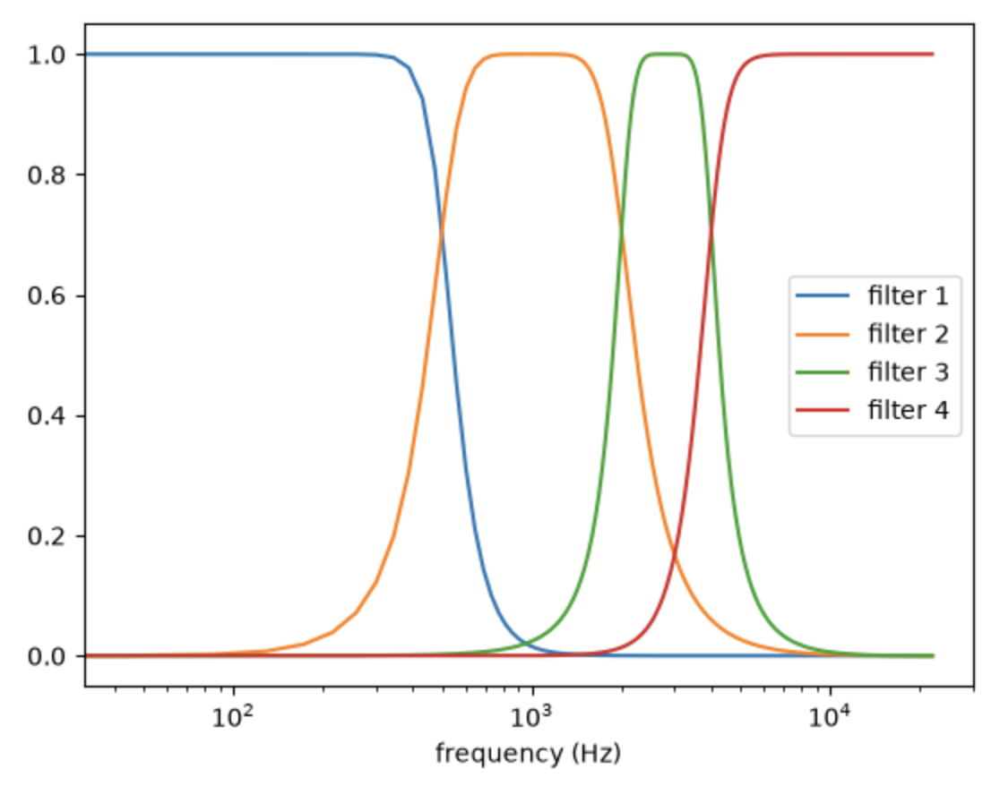

In [3]:
from IPython.display import Image
Image(filename='./assets/result_filters.png', width=600)

1.3) Charger et filtrer le fichier audio speech.wav à l'aide du banc de filtre. Écouter la sortie de chaque bande de fréquence pour valider. Sommer ces sorties et écouter l'audio reconstruit pour vérifier qu'il ressemble à l'original.

### 2. Vocoder

2.1) Charger les fichiers speech.wav (signal modulant) et chords.wav (porteuse), les filtrer avec le banc de filtre. 

2.2) Créer une boucle pour itérer sur le contenu de ces audios (en parralèle sur toutes les bandes de fréquences) par blocks de 512 samples. Pour chaque itération, calculer la RMS (root mean square) pour chaque bande de fréquence du signal modulant. Appliquer ces gains aux bandes de la porteuse. Sommer les bandes de la porteuse pour obtenir un buffer (array) audio mono.

2.3) Pour chaque itération, ajouter ce buffer à votre sortie : un array que vous aurez créé et dimensionné avant d'entrer dans la boucle.

À ce stade vous devriez obtenir :

In [4]:
fs, audio = scipy.io.wavfile.read('./assets/result_1.wav')
display(Audio(audio, rate=fs))

### 3. Zipper noise 

Les craquements (zipper noises) qu'on entend sont liés aux variations abruptes/discontinues du gain entre chaque block / buffer.

3.1) À l'aide du code ci-dessous, appliquer une rampe sur le gain au sein de chaque block : démarrant à la valeur finale du block précédent, s'achevant à la valeur cible du block courant.

3.2) (optionnel) Minimiser la durée de cette rampe pour qu'elle permette de créer un vocodeur réactif même lorsque la taille des blocks choisie est grande devant 512.

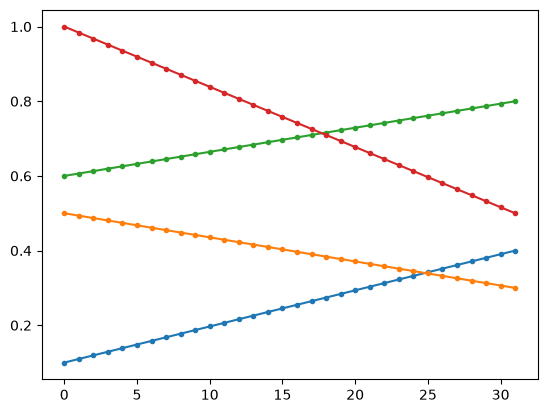

In [5]:
import matplotlib.pyplot as plt
import numpy as np

block_size = 32
gains_old = [0.1, 0.5, 0.6, 1.0]
gains = [0.4, 0.3, 0.8, 0.5]
gains_out = np.linspace(gains_old, gains, block_size)

plt.plot(gains_out, '.-')
plt.show()

À ce stade vous devriez obtenir :

In [6]:
fs, audio = scipy.io.wavfile.read('./assets/result_2.wav')
display(Audio(audio, rate=fs))

### 4. Augmenter le nombre de filtres

4.1) Pour obtenir un résultat plus intelligible (i.e. préserver les formants de la voix), augmenter le nombre de filtres utilisés, e.g. 16 à l'aide du code ci-dessous.

In [7]:
# define N-band filter bank
order = 6
n_bands = 16
edges = np.geomspace(200, 8000, n_bands - 1)
# first band
filter_specs = [ {'btype': 'low', 'Wn': edges[0], 'order': order} ]
# middle band passes
for f_low, f_high in zip(edges[:-1], edges[1:]):
    filter_specs.append({'btype': 'bandpass', 'Wn': [f_low, f_high], 'order': order // 2})
# last band
filter_specs.append({'btype': 'high', 'Wn': edges[-1], 'order': order})

À ce stade vous devriez obtenir l'audio présenté en introduction.

### 5. Cleanup

5.1) Nettoyer et factorisez votre code en encapsulant les opérations redondantes et/ou conceptuellement simple dans des fonctions, par exemple : 
- get_filter_bank_matrix(specs, fs)
- extract_ab_from_matrix(coefs, i)
- plot_filter_bank(coefs, fs)
- apply_filter_bank(audio_in, coefs)

5.2) Commenter votre code.

## Correction

In [8]:
# import
from IPython.display import Audio
import scipy
import matplotlib.pyplot as plt
import numpy as np
import math

In [ ]:
# load audio file, downmix, normalise
def audioread(filepath):
    # load
    fs, audio = scipy.io.wavfile.read(filepath)
    # downmix
    if( len(audio.shape) > 1):
        audio = audio[:, 1]
    # normalise
    audio = audio / np.max(np.abs(audio))
    return fs, audio

# play audio from numpy array
def playsound(audio, fs):
    # normalise
    audio = audio / np.max(np.abs(audio))
    # play
    display(Audio(audio, rate=fs))

# get matrix of iir filter coefs from filter specification
def filter_bank(specs, fs):
    # create filter bank
    coefs = np.zeros((len(specs), 2*(order+1)))
    for i_filter in range(len(specs)):
        # init locals
        spec = specs[i_filter]
        # get coefs
        b, a = scipy.signal.iirfilter(N = spec['order'], Wn = spec['Wn'], fs = fs, btype = spec['btype'], ftype = 'butter')
        # save to locals
        coefs[i_filter, :] = np.concat((a, b))
    return coefs

# extract iir coefs from matrix of iir filters
def get_ab(coefs, i):
    n = coefs.shape[1]//2
    a = coefs[i, 0:n]
    b = coefs[i, n:]
    return b, a

# plot filter bank
def plot_filter(coefs, fs):
    # init locals
    n = coefs.shape[0]
    # loop over filters
    for i_filter in range(n):
        # get coefs
        b, a = get_ab(coefs, i_filter)
        # plot frequency response
        freqs, H = scipy.signal.freqz(b, a, fs=fs)
        plt.plot(freqs, np.abs(H), label=f'filter {i_filter+1}')

    # format plot
    plt.xlabel('frequency (Hz)')
    plt.xscale('log')
    plt.legend()
    plt.show()

# apply filter to input audio, return matrix of filtered audio
def filter(audio_in, coefs):
    # init locals
    n = coefs.shape[0]
    audio_bands = np.zeros((n, len(audio_in)))
    # loop over filters
    for i_filter in range(n):
        # get coefs
        b, a = get_ab(coefs, i_filter)
        # apply filter
        buffer = scipy.signal.lfilter(b, a, audio_in)
        # save to locals
        audio_bands[i_filter, :] = buffer
    return audio_bands

def plot_audio(audio, fs):
    t = np.arange(len(audio))/fs
    plt.plot(t, audio)
    plt.xlabel('time (sec)')
    plt.show()


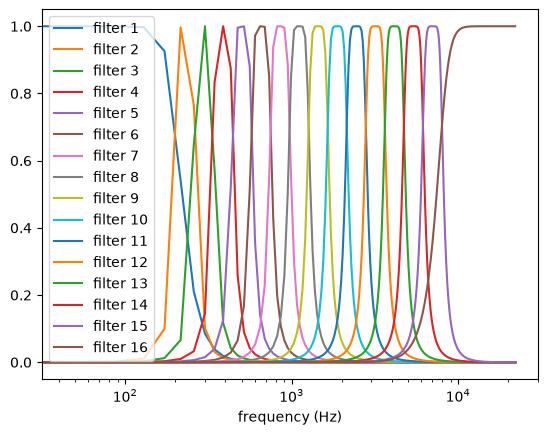

filter 1


filter 4


filter 7


filter 10


filter 13


filter 16


summed audio output


In [10]:
# load audio 
fs, audio_in = audioread('./assets/speech.wav')

# debug: truncate
audio_in = audio_in[0:fs]

# play sounds
playsound(audio_in, fs)

# # define filter: 4 bands
# order = 6
# filter_specs = [
#     {'btype': 'low', 'Wn': 500, 'order': order},
#     {'btype': 'bandpass', 'Wn': [500, 2000], 'order': order//2},
#     {'btype': 'bandpass', 'Wn': [2000, 4000], 'order': order//2},
#     {'btype': 'high', 'Wn': 4000, 'order': order},
# ]

# define N-band filter bank
order = 6
n_bands = 16
edges = np.geomspace(200, 8000, n_bands - 1)
# first band
filter_specs = [ {'btype': 'low', 'Wn': edges[0], 'order': order} ]
# middle band passes
for f_low, f_high in zip(edges[:-1], edges[1:]):
    filter_specs.append({'btype': 'bandpass', 'Wn': [f_low, f_high], 'order': order // 2})
# last band
filter_specs.append({'btype': 'high', 'Wn': edges[-1], 'order': order})

# create filter bank
filter_coefs = filter_bank(filter_specs, fs)

# plot filter bank
plot_filter(filter_coefs, fs)

# apply filter bank
audio_bands = filter(audio_in, filter_coefs)

# debug play
n = audio_bands.shape[0]
for i_filter in np.arange(0, n, 3):
    print(f'filter {i_filter+1}')
    buffer = audio_bands[i_filter, :]
    display(Audio(buffer, rate=fs))

# debug play re-summed audio
audio_out = np.sum(audio_bands, axis=0)
print('summed audio output')
playsound(audio_out, fs)

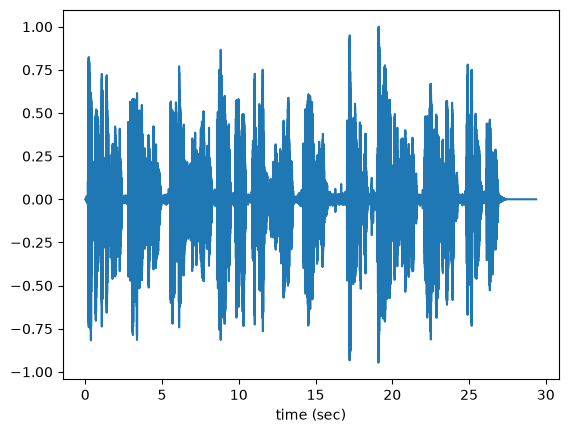

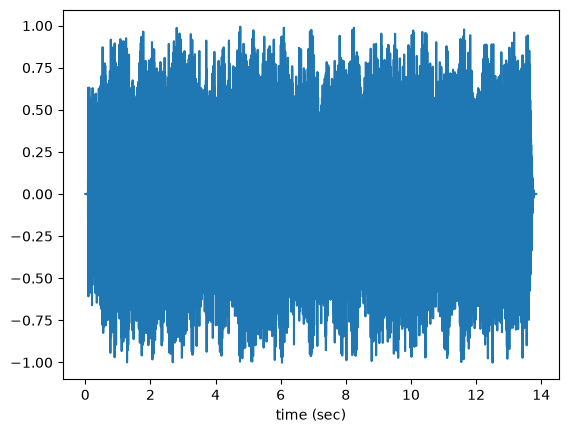

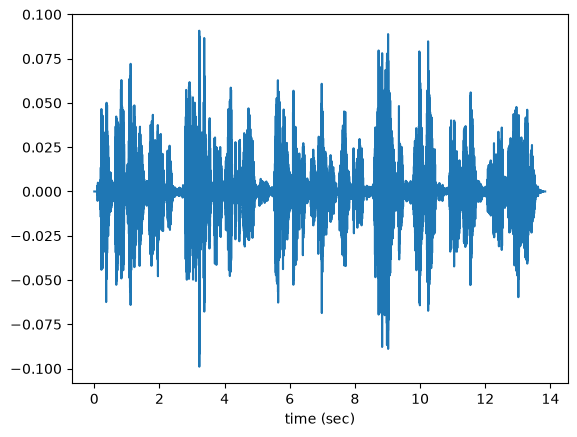

In [11]:
# load audio (modulator is voice, carrier is keyboard chords)
fs, modulator = audioread('./assets/speech.wav')
fs2, carrier = audioread('./assets/chords.wav')

# resample 
if( fs != fs2):
    carrier = scipy.signal.resample_poly(carrier, fs, fs2)

# play sounds
playsound(modulator, fs)
plot_audio(modulator, fs)
playsound(carrier, fs)
plot_audio(carrier, fs)

# filter 
filter_coefs = filter_bank(filter_specs, fs)
modulator_bands = filter(modulator, filter_coefs)
carrier_bands = filter(carrier, filter_coefs)

# init locals
block_size = 512
n_blocks = min(len(modulator), len(carrier)) // block_size
audio_out = np.zeros(n_blocks * block_size)
previous_gains = np.zeros(modulator_bands.shape[0])

# loop over blocks
for i_block in range(n_blocks):

    # init locals
    start = i_block*block_size 
    end = start + block_size
    modulator_bands_buffer = modulator_bands[:, start:end]
    carrier_bands_buffer = carrier_bands[:, start:end]

    # get per-band gains modulator (amplitudes)
    gains = np.sqrt(np.mean(modulator_bands_buffer**2, axis=1))

    # create smooth gain transitions (full block duration)
    gain_envelopes = np.linspace(previous_gains, gains, block_size)

    # create smooth gain transitions (minimize cross-fade duration)
    n_fade = min(256, block_size)
    gains_fade = np.linspace(previous_gains, gains, n_fade)
    gains_constant = gains * np.ones((len(gains), block_size - n_fade)).T
    gain_envelopes = np.concat((gains_fade, gains_constant))

    # save to output
    audio_out[start:end] = np.sum(carrier_bands_buffer * gain_envelopes.T, axis=0)

    # update locals
    previous_gains = gains

plt.show()

# play audio 
playsound(audio_out, fs)
plot_audio(audio_out, fs)
